Decomposition methods rest on one fact about polyhedra: every point of one is a convex combination
of its **extreme points** (corners) plus a non-negative combination of its **extreme rays** (edges that
run off to infinity). Benders decomposition uses that fact to add *rows* to a master problem, one cut
per extreme point or ray. Dantzig-Wolfe decomposition uses it to add *columns*, one variable per
extreme point. This lesson looks at the extreme points directly, then generates columns for the
cutting stock problem.

To run it yourself: `pip install gurobipy numpy pandas matplotlib`. The free licence that comes with
`pip install gurobipy` is enough for everything here.

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gurobipy as gp
from gurobipy import GRB

## Extreme points and extreme rays

Take the mixed-integer program from the [Benders lesson](/resources/bender-decomp/):

$$\begin{aligned} \max\ 2x_1 + x_2 + 13x_3 + 7y_1 + 5y_2 \quad \text{s.t.}\quad 9x_1 + 4x_2 + 14x_3 + 35y_1 + 24y_2 &\le 80 \\ -x_1 - 2x_2 + 3x_3 - 3y_1 + 4y_2 &\le 10 \\ x \ge 0 \text{ and integer},\quad y &\ge 0 \end{aligned}$$

With $x$ fixed, the dual of the problem in $y$ has the region
$U = \{u \ge 0 : 35u_1 - 3u_2 \ge 7,\ 24u_1 + 4u_2 \ge 5\}$. Write it as $Gu \ge h$, four rows.

In [2]:
G = np.array([[35.0, -3.0],
              [24.0,  4.0],
              [ 1.0,  0.0],
              [ 0.0,  1.0]])
h = np.array([7.0, 5.0, 0.0, 0.0])
print("G is", G.shape, "| h =", h)

G is (4, 2) | h = [7. 5. 0. 0.]


A corner is where two of the four boundary lines cross *and* every other constraint still holds.
Try every pair. **Predict:** how many of the six pairs give a corner?

In [3]:
corners = []
for i, j in itertools.combinations(range(4), 2):
    M = G[[i, j]]
    if abs(np.linalg.det(M)) < 1e-12:
        continue
    p = np.linalg.solve(M, h[[i, j]])
    ok = np.all(G @ p >= h - 1e-9)
    print(f"rows {i},{j}: u = ({p[0]:.4f}, {p[1]:.4f})  {'corner' if ok else 'outside U'}")
    if ok:
        corners.append(p)
corners = np.array(corners)

rows 0,1: u = (0.2028, 0.0330)  corner
rows 0,2: u = (0.0000, -2.3333)  outside U
rows 0,3: u = (0.2000, 0.0000)  outside U
rows 1,2: u = (0.0000, 1.2500)  outside U
rows 1,3: u = (0.2083, 0.0000)  corner
rows 2,3: u = (0.0000, 0.0000)  outside U


A ray is a direction $d$ you can travel forever without leaving $U$: $Gd \ge 0$, the same rows with
the right-hand side set to zero. Scale it so $d_1 + d_2 = 1$. An extreme ray makes one of those
homogeneous rows tight.

In [4]:
rays = []
for i in range(4):
    d = np.linalg.solve(np.array([G[i], [1.0, 1.0]]), np.array([0.0, 1.0]))
    ok = np.all(G @ d >= -1e-9)
    print(f"row {i} tight: d = ({d[0]:.4f}, {d[1]:.4f})  {'extreme ray' if ok else 'leaves U'}")
    if ok:
        rays.append(d)
rays = np.array(rays)

row 0 tight: d = (0.0789, 0.9211)  extreme ray
row 1 tight: d = (-0.2000, 1.2000)  leaves U
row 2 tight: d = (0.0000, 1.0000)  leaves U
row 3 tight: d = (1.0000, 0.0000)  extreme ray


The region, its corners and its rays.

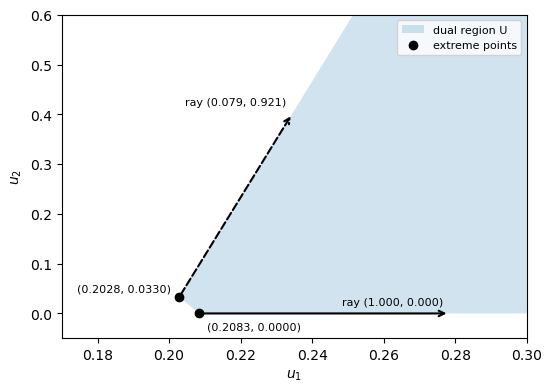

In [5]:
top = (35 * 0.3 - 7) / 3                     # the steep edge where it meets u1 = 0.3
region = np.array([corners[0], corners[1], [0.3, 0.0], [0.3, top]])
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill(region[:, 0], region[:, 1], alpha=0.2, label="dual region U")
ax.plot(corners[:, 0], corners[:, 1], "ko", label="extreme points")
for p, d, length, style in [(corners[0], rays[0], 0.4, "--"), (corners[1], rays[1], 0.07, "-")]:
    ax.annotate("", xy=p + length * d, xytext=p, arrowprops=dict(arrowstyle="->", linestyle=style, lw=1.5))
    ax.annotate(f"ray ({d[0]:.3f}, {d[1]:.3f})", p + length * d, textcoords="offset points",
                xytext=(-4, 6), ha="right", fontsize=8)
for p, offset in zip(corners, [(-6, 4), (6, -12)]):
    ax.annotate(f"({p[0]:.4f}, {p[1]:.4f})", p, textcoords="offset points", xytext=offset,
                ha="right" if offset[0] < 0 else "left", fontsize=8)
ax.set(xlim=(0.17, 0.3), ylim=(-0.05, 0.6), xlabel="$u_1$", ylabel="$u_2$")
ax.legend(loc="upper right", fontsize=8)
plt.show()
# alt: The dual region is an unbounded wedge with two corners close together, (0.2028, 0.0330) and (0.2083, 0); one ray runs right along the u1 axis from (0.2083, 0) and the other climbs steeply along the region's left edge, in direction (0.079, 0.921), from (0.2028, 0.0330).

For fixed $x$, the $y$-problem's best value is the dual's minimum of $r_1 u_1 + r_2 u_2$ over $U$, where
$r_1 = 80 - 9x_1 - 4x_2 - 14x_3$ and $r_2 = 10 + x_1 + 2x_2 - 3x_3$. A linear function's minimum over
$U$ sits at a corner, unless it falls forever along a ray. So the whole problem is

$$\begin{aligned} \max\ 2x_1 + x_2 + 13x_3 + z \quad \text{s.t.}\quad z &\le r_1 p_1 + r_2 p_2 \ \text{ for each corner } p \\ 0 &\le r_1 d_1 + r_2 d_2 \ \text{ for each ray } d, \end{aligned}$$

with no $y$ at all: two optimality cuts and two feasibility cuts. **Predict:** does this four-row
model give the same optimum as the original?

In [6]:
allcuts = gp.Model("all_cuts")
allcuts.Params.OutputFlag = 0
x = allcuts.addVars(3, vtype=GRB.INTEGER, name="x")
z = allcuts.addVar(lb=-GRB.INFINITY, name="z")
r1 = 80 - 9 * x[0] - 4 * x[1] - 14 * x[2]
r2 = 10 + x[0] + 2 * x[1] - 3 * x[2]
for p in corners:
    allcuts.addConstr(z <= r1 * p[0] + r2 * p[1])
for d in rays:
    allcuts.addConstr(r1 * d[0] + r2 * d[1] >= 0)
allcuts.setObjective(2 * x[0] + x[1] + 13 * x[2] + z, GRB.MAXIMIZE)
allcuts.optimize()
print(f"all-cuts master: value = {allcuts.ObjVal:g}, x = {[round(x[i].X) for i in range(3)]}, z = {z.X:g}")

Restricted license - for non-production use only - expires 2027-11-29


all-cuts master: value = 58, x = [0, 6, 4], z = 0


And the original model, solved in one piece:

In [7]:
orig = gp.Model("original")
orig.Params.OutputFlag = 0
xo = orig.addVars(3, vtype=GRB.INTEGER, name="x")
yo = orig.addVars(2, name="y")
orig.addConstr(9 * xo[0] + 4 * xo[1] + 14 * xo[2] + 35 * yo[0] + 24 * yo[1] <= 80)
orig.addConstr(-xo[0] - 2 * xo[1] + 3 * xo[2] - 3 * yo[0] + 4 * yo[1] <= 10)
orig.setObjective(2 * xo[0] + xo[1] + 13 * xo[2] + 7 * yo[0] + 5 * yo[1], GRB.MAXIMIZE)
orig.optimize()
print(f"original:        value = {orig.ObjVal:g}, x = {[round(xo[i].X) for i in range(3)]}")

original:        value = 58, x = [0, 6, 4]


Here $U$ has two corners and two rays, so writing every cut down is easy. A larger $U$ can have
more corners than anyone could list. Benders generates the rows only as the master needs them.
Dantzig-Wolfe turns the same idea sideways: write a set of *primal* variables as a combination of
the corners of their feasible set, give each corner a variable (a column), and generate the columns
only as they are needed. That is column generation.

## Column generation: the cutting stock problem

Rods are 218 cm long. Customers need 44 pieces of 81 cm, 3 pieces of 70 cm and 48 pieces of 68 cm.
A **pattern** $a = (a_1, a_2, a_3)$ says how many pieces of each length one rod is cut into; it fits
when $81a_1 + 70a_2 + 68a_3 \le 218$. With $\lambda_p$ rods cut by pattern $p$, the master problem is

$$\min\ \sum_p \lambda_p \quad \text{s.t.}\quad \sum_p a_{ip}\lambda_p \ge d_i \ \text{ for each length } i,\quad \lambda \ge 0 .$$

Start with three wasteful patterns: one piece per rod.

In [8]:
w = np.array([81, 70, 68])
demand = np.array([44, 3, 48])
L = 218
patterns = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
print("lengths", w, "| demand", demand, "| start patterns", patterns)

lengths [81 70 68] | demand [44  3 48] | start patterns [[1, 0, 0], [0, 1, 0], [0, 0, 1]]


### The restricted master LP

"Restricted" because it holds only the patterns found so far. Its duals $\pi_i$ price one piece of
each length. **Predict** the number of rods and the three duals.

In [9]:
master = gp.Model("master")
master.Params.OutputFlag = 0
lam = [master.addVar(obj=1) for p in patterns]
rows = [master.addConstr(gp.quicksum(p[i] * lam[j] for j, p in enumerate(patterns)) >= demand[i])
        for i in range(3)]
master.optimize()
pi = [con.Pi for con in rows]
print(f"rods = {master.ObjVal:g}, duals = {np.round(pi, 4)}")

rods = 95, duals = [1. 1. 1.]


### Pricing: a knapsack problem

A new pattern $a$ costs one rod and is worth $\pi^\top a$ at today's prices, so its reduced cost is
$1 - \pi^\top a$. The pattern with the most negative reduced cost solves a knapsack problem:
$\max\ \pi^\top a$ subject to $81a_1 + 70a_2 + 68a_3 \le 218$, $a$ integer. **Predict** the pattern.

In [10]:
knap = gp.Model("pricing")
knap.Params.OutputFlag = 0
a = knap.addVars(3, vtype=GRB.INTEGER, name="a")
knap.addConstr(gp.quicksum(w[i] * a[i] for i in range(3)) <= L)
knap.setObjective(gp.quicksum(pi[i] * a[i] for i in range(3)), GRB.MAXIMIZE)
knap.optimize()
new = [round(a[i].X) for i in range(3)]
print(f"new pattern = {new}, uses {w @ new} cm, reduced cost = {1 - knap.ObjVal:g}")

new pattern = [0, 0, 3], uses 204 cm, reduced cost = -2


### Add the column

The new pattern becomes a new variable, entering each demand row with its piece count. **Predict**
the new number of rods.

In [11]:
patterns.append(new)
lam.append(master.addVar(obj=1, column=gp.Column(new, rows)))
master.optimize()
pi = [con.Pi for con in rows]
print(f"rods = {master.ObjVal:g}, duals = {np.round(pi, 4)}")

rods = 63, duals = [1.     1.     0.3333]


## Now the streamlined version

One round is solve, price, add. The loop repeats it until no pattern has a negative reduced cost. It
starts again from the three one-piece patterns, so its first line should match the round above.

In [12]:
patterns = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
master = gp.Model("master")
master.Params.OutputFlag = 0
lam = [master.addVar(obj=1) for p in patterns]
rows = [master.addConstr(gp.quicksum(p[i] * lam[j] for j, p in enumerate(patterns)) >= demand[i])
        for i in range(3)]
for it in range(1, 50):
    master.optimize()
    pi = [con.Pi for con in rows]
    knap.setObjective(gp.quicksum(pi[i] * a[i] for i in range(3)), GRB.MAXIMIZE)
    knap.optimize()
    new = [round(a[i].X) for i in range(3)]
    rc = 1 - knap.ObjVal
    print(f"round {it}: rods (LP) = {master.ObjVal:5.2f}  duals = {np.round(pi, 3)}  best pattern = {new}  reduced cost = {rc:.3f}")
    if rc > -1e-9:
        break
    patterns.append(new)
    lam.append(master.addVar(obj=1, column=gp.Column(new, rows)))

round 1: rods (LP) = 95.00  duals = [1. 1. 1.]  best pattern = [0, 0, 3]  reduced cost = -2.000
round 2: rods (LP) = 63.00  duals = [1.    1.    0.333]  best pattern = [0, 3, 0]  reduced cost = -2.000
round 3: rods (LP) = 61.00  duals = [1.    0.333 0.333]  best pattern = [2, 0, 0]  reduced cost = -1.000
round 4: rods (LP) = 39.00  duals = [0.5   0.333 0.333]  best pattern = [1, 0, 2]  reduced cost = -0.167
round 5: rods (LP) = 35.00  duals = [0.5   0.333 0.25 ]  best pattern = [2, 0, 0]  reduced cost = 0.000


The patterns the master ended with, and how many rods it cuts by each.

In [13]:
table = pd.DataFrame(patterns, columns=["81 cm", "70 cm", "68 cm"])
table["cm used"] = table[["81 cm", "70 cm", "68 cm"]].values @ w
table["rods (LP)"] = [round(v.X, 3) for v in lam]
table

,81 cm,70 cm,68 cm,cm used,rods (LP)
0,1,0,0,81,0.0
1,0,1,0,70,0.0
2,0,0,1,68,0.0
3,0,0,3,204,0.0
4,0,3,0,210,1.0
5,2,0,0,162,10.0
6,1,0,2,217,24.0


### An integer solution from the final master

Rods come whole. Make every $\lambda_p$ integer and re-solve the master over the same patterns.
**Predict:** how many rods, compared with the LP's?

In [14]:
for v in lam:
    v.VType = GRB.INTEGER
master.optimize()
print(f"rods (integer) = {master.ObjVal:g}, by pattern = {[round(v.X) for v in lam]}")

rods (integer) = 35, by pattern = [0, 0, 0, 0, 1, 10, 24]


Column generation never looked at most patterns. This problem is small enough to list them all, so
check: solve the integer master with every pattern that fits. **Predict** how many patterns there are.

In [15]:
every = [p for p in itertools.product(range(3), range(4), range(4)) if 0 < w @ p <= L]
check = gp.Model("every_pattern")
check.Params.OutputFlag = 0
mu = check.addVars(len(every), vtype=GRB.INTEGER)
for i in range(3):
    check.addConstr(gp.quicksum(p[i] * mu[j] for j, p in enumerate(every)) >= demand[i])
check.setObjective(mu.sum(), GRB.MINIMIZE)
check.optimize()
print(f"{len(every)} patterns fit | rods (integer, every pattern) = {check.ObjVal:g}")

14 patterns fit | rods (integer, every pattern) = 35


- Compare the LP's rods by pattern with the integer ones. When could an integer master over only
  the generated patterns miss a better solution that needs a pattern it never generated?
- The last round's best pattern was already in the master. Why does that mean the LP is optimal over
  *all* patterns, not just the ones generated?
- In the all-cuts model, one corner of $U$ never decided the answer. Which one, and how would
  Benders have found that out?